# Project 3: Few-shot prompting and object hallucination in small VLMs

**Research question:** Does giving a small vision-language model a few in-context examples (0 / 1 / 3 / 5 shots) reduce object hallucination on the POPE benchmark?

**Setup**
- Models: `Qwen/Qwen2-VL-2B-Instruct` (default) or `HuggingFaceTB/SmolVLM-Instruct`
- 4-bit NF4 quantization with bitsandbytes, runs on a single free T4 (Colab or Kaggle)
- Benchmark: POPE (COCO, three splits: random, popular, adversarial)
- Metrics: accuracy, precision, recall, F1, "yes" ratio, hallucination rate (false positive rate), AUROC, bootstrap 95% CIs, McNemar test vs 0-shot
- Output: results file, figures and a short `report.md`, all saved in Google Drive



## 1. Install libraries

In [1]:
# Install / upgrade the libraries we need (-q keeps the output short)
# transformers: model + processor code, accelerate: device placement,
# bitsandbytes: 4-bit quantization, datasets: POPE download,
# num2words: needed by the SmolVLM processor, scipy/sklearn: statistics
!pip install -q -U "transformers>=4.49" accelerate bitsandbytes datasets num2words scipy scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 6.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 104.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 102.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 14.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


## 2. Configuration (change things only here)

In [2]:
import os  # file paths and environment variables
import sys  # used to detect whether we are on Colab

# Reduce GPU memory fragmentation; must be set BEFORE torch is imported
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# Hide a harmless tokenizers warning that appears when using multiple workers
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ---------------- Experiment settings ----------------
MODEL_NAME = "qwen2-vl-2b"          # "qwen2-vl-2b" or "smolvlm"
SHOTS = [0, 1, 3, 5]                # numbers of in-context examples to test
CATEGORIES = ["random", "popular", "adversarial"]  # the three POPE splits
N_PER_CATEGORY = 300                # questions per split (max ~2940); 300 x 3 x 4 = 3600 forward passes
N_DEMO_IMAGES = 10                  # COCO images reserved ONLY for few-shot examples (never evaluated)
SEED = 42                           # global random seed for reproducibility

# ---------------- Memory settings ----------------
MAX_IMAGE_SIDE = 448                # images are shrunk so the longest side is at most this many pixels
QWEN_MIN_PIXELS = 128 * 28 * 28     # Qwen2-VL: lower bound on image area (controls visual tokens)
QWEN_MAX_PIXELS = 256 * 28 * 28     # Qwen2-VL: upper bound, about 256 visual tokens per image
CLEANUP_EVERY = 50                  # free cached GPU memory every N questions
SAVE_EVERY = 20                     # write results to Drive every N questions

# ---------------- Storage settings ----------------
CACHE_MODEL_IN_DRIVE = False        # True = keep a copy of the ~4.5 GB model in Drive (saves download time, costs Drive space)
PROJECT_FOLDER = "VLM_FewShot_POPE" # folder name inside your Drive

# Registry of supported models: HF repo id and modules that should NOT be quantized
MODEL_REGISTRY = {
    "qwen2-vl-2b": {
        "hf_id": "Qwen/Qwen2-VL-2B-Instruct",
        "skip_modules": ["visual", "lm_head"],  # keep vision encoder and output head in 16-bit for quality
    },
    "smolvlm": {
        "hf_id": "HuggingFaceTB/SmolVLM-Instruct",
        "skip_modules": ["vision_model", "connector", "lm_head"],  # same idea for SmolVLM
    },
}
assert MODEL_NAME in MODEL_REGISTRY, f"MODEL_NAME must be one of {list(MODEL_REGISTRY)}"
CFG = MODEL_REGISTRY[MODEL_NAME]  # settings of the chosen model

## 3. Mount Drive and create folders

In [3]:
# Detect the platform so the same notebook works on Colab, Kaggle or a local machine
try:
    from google.colab import drive  # only importable on Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_KAGGLE = os.path.exists("/kaggle/working")  # Kaggle always has this folder

if IN_COLAB:
    drive.mount("/content/drive")  # ask for Drive permission and mount it
    BASE_DIR = f"/content/drive/MyDrive/{PROJECT_FOLDER}"  # results survive session resets here
    LOCAL_DIR = "/content"  # fast local disk for temporary caches
elif IN_KAGGLE:
    BASE_DIR = f"/kaggle/working/{PROJECT_FOLDER}"  # saved when you "Save Version" on Kaggle
    LOCAL_DIR = "/kaggle/temp"
else:
    BASE_DIR = os.path.abspath(PROJECT_FOLDER)
    LOCAL_DIR = os.path.abspath(".cache_local")

FIG_DIR = os.path.join(BASE_DIR, "figures")  # plots go here
DATA_CACHE = os.path.join(LOCAL_DIR, "hf_datasets")  # dataset cache (local, re-downloaded each session)
# Model cache: Drive if requested, otherwise local disk
MODEL_CACHE = os.path.join(BASE_DIR, "hf_models") if CACHE_MODEL_IN_DRIVE else os.path.join(LOCAL_DIR, "hf_models")
for d in [BASE_DIR, FIG_DIR, DATA_CACHE, MODEL_CACHE]:
    os.makedirs(d, exist_ok=True)  # create folder if it does not exist

# Files that make resuming possible
EVAL_SET_PATH = os.path.join(BASE_DIR, "eval_set.csv")  # fixed list of evaluation questions
DEMO_SET_PATH = os.path.join(BASE_DIR, "demo_set.csv")  # fixed pool of few-shot examples
RESULTS_PATH = os.path.join(BASE_DIR, f"results_{MODEL_NAME}.jsonl")  # one line per answered question
ERRORS_PATH = os.path.join(BASE_DIR, f"errors_{MODEL_NAME}.jsonl")  # questions that failed (retried next run)
print("Saving everything to:", BASE_DIR)

Mounted at /content/drive
Saving everything to: /content/drive/MyDrive/VLM_FewShot_POPE


## 4. Imports, seeds and GPU check

In [4]:
import gc  # manual garbage collection to free RAM
import json  # results are stored as JSON lines
import math  # small math helpers
import time  # timing
import random  # deterministic demo sampling
import inspect  # check which arguments the model forward accepts
import numpy as np  # numeric arrays
import pandas as pd  # tables
import torch  # deep learning framework
from tqdm.auto import tqdm  # progress bars

random.seed(SEED)  # Python RNG
np.random.seed(SEED)  # NumPy RNG
torch.manual_seed(SEED)  # PyTorch RNG

assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > T4 GPU"
DEVICE = torch.device("cuda:0")  # we use exactly one GPU
major, _ = torch.cuda.get_device_capability(0)  # T4 = 7.x, A100 = 8.x
# T4 has no real bfloat16 support, so use float16 there; newer GPUs use bfloat16
COMPUTE_DTYPE = torch.bfloat16 if major >= 8 else torch.float16
print("GPU:", torch.cuda.get_device_name(0), "| compute dtype:", COMPUTE_DTYPE)
print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

def gpu_mem():
    # Return a short string with currently allocated and reserved GPU memory
    return f"alloc {torch.cuda.memory_allocated() / 1e9:.2f} GB | reserved {torch.cuda.memory_reserved() / 1e9:.2f} GB"

def cleanup():
    # Free Python objects and cached GPU blocks
    gc.collect()
    torch.cuda.empty_cache()

GPU: Tesla T4 | compute dtype: torch.float16
GPU memory: 15.6 GB


## 5. Load POPE and build a fixed evaluation set

In [5]:
from datasets import load_dataset  # Hugging Face datasets library

# lmms-lab/POPE: 9000 COCO questions (3000 per split), images are embedded in the dataset
pope = load_dataset("lmms-lab/POPE", split="test", cache_dir=DATA_CACHE)
print(pope)

# Read ONLY the text columns into pandas; images stay on disk and are decoded one at a time later
meta = pope.select_columns(["question_id", "question", "answer", "image_source", "category"]).to_pandas()
meta["row_idx"] = np.arange(len(meta))  # remember the original row to fetch the image later
meta["answer"] = meta["answer"].str.strip().str.lower()  # normalise labels to "yes" / "no"
meta["category"] = meta["category"].str.strip().str.lower()  # normalise split names
meta["question_id"] = meta["question_id"].astype(str)  # string ids are safer as dict keys
print(meta.groupby(["category", "answer"]).size())

README.md:   0%|          | 0.00/2.16k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'question_id', 'question', 'answer', 'image_source', 'image', 'category'],
    num_rows: 9000
})
category     answer
adversarial  no        1500
             yes       1500
popular      no        1500
             yes       1500
random       no        1500
             yes       1500
dtype: int64


In [6]:
if os.path.exists(EVAL_SET_PATH) and os.path.exists(DEMO_SET_PATH):
    # Resume case: reuse the exact same questions and demos as the first run
    eval_df = pd.read_csv(EVAL_SET_PATH, dtype={"question_id": str})
    demo_df = pd.read_csv(DEMO_SET_PATH, dtype={"question_id": str})
    print("Loaded existing eval/demo sets from Drive (resume mode).")
else:
    rng = np.random.RandomState(SEED)  # seeded RNG for the split
    all_images = sorted(meta["image_source"].unique())  # list of distinct COCO images
    demo_images = set(rng.choice(all_images, N_DEMO_IMAGES, replace=False))  # images reserved for demos
    demo_df = meta[meta["image_source"].isin(demo_images)].copy()  # few-shot example pool
    pool = meta[~meta["image_source"].isin(demo_images)]  # evaluation pool: no image overlap with demos

    parts = []
    for cat in CATEGORIES:
        sub = pool[pool["category"] == cat]  # questions of one split
        n_half = min(N_PER_CATEGORY // 2, (sub["answer"] == "yes").sum(), (sub["answer"] == "no").sum())
        for lab in ["yes", "no"]:
            # Balanced sample: half "yes" and half "no" questions
            parts.append(sub[sub["answer"] == lab].sample(n=n_half, random_state=SEED))
    eval_df = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)  # shuffle order

    eval_df.to_csv(EVAL_SET_PATH, index=False)  # freeze the eval set in Drive
    demo_df.to_csv(DEMO_SET_PATH, index=False)  # freeze the demo pool in Drive
    print("Created and saved new eval/demo sets.")

print("Eval questions per split:\n", eval_df.groupby(["category", "answer"]).size())
print("Demo pool size:", len(demo_df), "| demo images:", demo_df["image_source"].nunique())
# Safety check: no evaluation image is ever used as a demo (prevents leakage)
assert not set(eval_df["image_source"]) & set(demo_df["image_source"]), "Leakage between demos and eval!"

Loaded existing eval/demo sets from Drive (resume mode).
Eval questions per split:
 category     answer
adversarial  no        150
             yes       150
popular      no        150
             yes       150
random       no        150
             yes       150
dtype: int64
Demo pool size: 180 | demo images: 10


## 6. Image loading and few-shot demo selection

In [7]:
def load_image(row_idx, max_side=MAX_IMAGE_SIDE):
    # Decode a single image from the dataset, convert to RGB and shrink it in place
    img = pope[int(row_idx)]["image"].convert("RGB")
    img.thumbnail((max_side, max_side))  # keeps aspect ratio, never upsizes
    return img

# Cache demo images in RAM: only N_DEMO_IMAGES small images, so this is cheap
DEMO_IMG_CACHE = {}
def demo_image(image_source, row_idx):
    if image_source not in DEMO_IMG_CACHE:
        DEMO_IMG_CACHE[image_source] = load_image(row_idx)
    return DEMO_IMG_CACHE[image_source]

def pick_demos(k, category, qid):
    # Choose k demos from the same POPE split, balanced between "yes" and "no".
    # The RNG is seeded by (category, question, k) so a resumed run picks the same demos.
    if k == 0:
        return []
    r = random.Random(f"{SEED}-{category}-{qid}-{k}")
    pool = demo_df[demo_df["category"] == category]
    yes_pool = pool[pool["answer"] == "yes"].to_dict("records")
    no_pool = pool[pool["answer"] == "no"].to_dict("records")
    n_yes = k // 2 + (r.randint(0, 1) if k % 2 else 0)  # odd k: the extra example is yes or no at random
    picks = r.sample(yes_pool, n_yes) + r.sample(no_pool, k - n_yes)
    r.shuffle(picks)  # random order so the last demo label is not always the same
    return picks

INSTRUCTION = "Answer the question with a single word: Yes or No."

def user_turn(question):
    # One user message = one image placeholder + the question text
    return {"role": "user", "content": [{"type": "image"}, {"type": "text", "text": f"{question} {INSTRUCTION}"}]}

def build_conversation(demos, question, query_img):
    # Few-shot examples are given as previous turns of the chat, each answered correctly
    messages, images = [], []
    for d in demos:
        messages.append(user_turn(d["question"]))
        messages.append({"role": "assistant", "content": [{"type": "text", "text": "Yes" if d["answer"] == "yes" else "No"}]})
        images.append(demo_image(d["image_source"], d["row_idx"]))
    messages.append(user_turn(question))  # the real test question comes last
    images.append(query_img)
    return messages, images  # images are in the same order as the image placeholders

## 7. Load the VLM in 4-bit

In [8]:
from transformers import AutoProcessor, BitsAndBytesConfig

# NF4 4-bit quantization with double quantization: the smallest memory footprint bitsandbytes offers
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,                      # store linear-layer weights in 4 bits
    bnb_4bit_quant_type="nf4",              # NormalFloat4, best quality for 4-bit
    bnb_4bit_use_double_quant=True,         # also quantize the quantization constants (saves ~0.4 bit/param)
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,   # matmuls run in fp16 on T4
    llm_int8_skip_modules=CFG["skip_modules"],  # keep vision tower and lm_head unquantized
)

if MODEL_NAME == "qwen2-vl-2b":
    from transformers import Qwen2VLForConditionalGeneration as ModelCls
    # min/max_pixels cap the number of visual tokens per image (main memory knob for Qwen2-VL)
    processor = AutoProcessor.from_pretrained(CFG["hf_id"], min_pixels=QWEN_MIN_PIXELS,
                                              max_pixels=QWEN_MAX_PIXELS, cache_dir=MODEL_CACHE)
else:
    try:
        from transformers import AutoModelForImageTextToText as ModelCls  # newer transformers
    except ImportError:
        from transformers import AutoModelForVision2Seq as ModelCls  # older transformers
    processor = AutoProcessor.from_pretrained(CFG["hf_id"], cache_dir=MODEL_CACHE)
    # SmolVLM normally cuts every image into many tiles; disabling it keeps ~81 tokens per image
    processor.image_processor.do_image_splitting = False

model = ModelCls.from_pretrained(
    CFG["hf_id"],
    quantization_config=bnb_config,  # apply 4-bit quantization while loading
    torch_dtype=COMPUTE_DTYPE,       # non-quantized parts in fp16
    device_map={"": 0},              # put the whole model on GPU 0
    low_cpu_mem_usage=True,          # stream weights so system RAM does not spike
    attn_implementation="sdpa",      # memory-efficient attention available on T4
    cache_dir=MODEL_CACHE,
)
model.eval()  # inference mode: disables dropout
tokenizer = processor.tokenizer  # text tokenizer inside the processor
cleanup()
print("Model loaded |", gpu_mem())
print(f"Model memory footprint: {model.get_memory_footprint() / 1e9:.2f} GB")

preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Model loaded | alloc 1.49 GB | reserved 1.56 GB
Model memory footprint: 1.46 GB


## 8. Yes/No scoring with a single forward pass
Instead of free-form generation we read the next-token probability of *Yes* vs *No*. This is one forward pass per question (fast), deterministic, and also gives a confidence score for AUROC.

In [9]:
def first_token_ids(words):
    # Token id of the first sub-token of each spelling variant
    ids = set()
    for w in words:
        t = tokenizer.encode(w, add_special_tokens=False)
        if t:
            ids.add(t[0])
    return sorted(ids)

YES_IDS = first_token_ids(["Yes", "yes", " Yes", " yes", "YES"])  # all ways the model may start "yes"
NO_IDS = first_token_ids(["No", "no", " No", " no", "NO"])  # all ways the model may start "no"
assert not set(YES_IDS) & set(NO_IDS), "Yes/No token ids overlap"
print("Yes ids:", YES_IDS, "| No ids:", NO_IDS)

FWD_PARAMS = inspect.signature(model.forward).parameters  # arguments the forward accepts
# Ask the model for logits of the LAST position only; full logits (seq_len x 150k vocab) would waste ~0.5 GB
if "logits_to_keep" in FWD_PARAMS:
    LOGIT_KW = {"logits_to_keep": 1}
elif "num_logits_to_keep" in FWD_PARAMS:
    LOGIT_KW = {"num_logits_to_keep": 1}
else:
    LOGIT_KW = {}
print("Extra forward kwargs:", LOGIT_KW)

def prepare_inputs(messages, images):
    # Turn the chat into the model's prompt text, then tokenize text + images together
    text = processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    inputs = processor(text=[text], images=images, return_tensors="pt").to(DEVICE)
    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(COMPUTE_DTYPE)  # match model dtype
    return inputs

@torch.inference_mode()  # no gradients: big memory saving
def score_yes_no(messages, images):
    inputs = prepare_inputs(messages, images)
    n_tokens = int(inputs["input_ids"].shape[1])  # prompt length, logged for analysis
    out = model(**inputs, use_cache=False, **LOGIT_KW)  # no KV cache needed for a single step
    logits = out.logits[0, -1].float()  # logits for the next token, in fp32 for stable softmax
    del out, inputs  # release GPU tensors immediately
    if not torch.isfinite(logits).all():
        raise FloatingPointError("Non-finite logits (fp16 overflow)")
    logp = torch.log_softmax(logits, dim=-1)
    lp_yes = torch.logsumexp(logp[YES_IDS], dim=0)  # total log-prob of all "yes" spellings
    lp_no = torch.logsumexp(logp[NO_IDS], dim=0)  # total log-prob of all "no" spellings
    p_yes = torch.sigmoid(lp_yes - lp_no).item()  # P(yes) renormalised over {yes, no}
    mass = (lp_yes.exp() + lp_no.exp()).item()  # how much probability went to yes/no at all
    return p_yes, mass, n_tokens

@torch.inference_mode()
def generate_text(messages, images, max_new_tokens=5):
    # Free-form greedy answer, used only for a sanity check
    inputs = prepare_inputs(messages, images)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    text = processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0]
    del out, inputs
    return text.strip()

Yes ids: [7414, 9454, 9693, 9834, 14004] | No ids: [902, 2152, 2308, 2753, 8996]
Extra forward kwargs: {'logits_to_keep': 1}


## 9. Sanity check on a few questions

In [10]:
for _, row in eval_df.head(3).iterrows():
    img = load_image(row["row_idx"])
    for k in [0, 3]:
        msgs, imgs = build_conversation(pick_demos(k, row["category"], row["question_id"]), row["question"], img)
        p, mass, n = score_yes_no(msgs, imgs)
        gen = generate_text(msgs, imgs)
        print(f"[{k}-shot] {row['question'][:60]:60s} | label={row['answer']:3s} | P(yes)={p:.3f} "
              f"| yes/no mass={mass:.2f} | gen='{gen}' | tokens={n}")
    del img
cleanup()
print(gpu_mem())

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[0-shot] Is there a zebra in the image?                               | label=yes | P(yes)=0.993 | yes/no mass=1.00 | gen='Yes' | tokens=218


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[3-shot] Is there a zebra in the image?                               | label=yes | P(yes)=0.991 | yes/no mass=1.00 | gen='Yes' | tokens=878
[0-shot] Is there a car in the image?                                 | label=no  | P(yes)=0.025 | yes/no mass=1.00 | gen='No' | tokens=249


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[3-shot] Is there a car in the image?                                 | label=no  | P(yes)=0.054 | yes/no mass=1.00 | gen='No' | tokens=908
[0-shot] Is there a cow in the image?                                 | label=no  | P(yes)=0.027 | yes/no mass=1.00 | gen='No' | tokens=217


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[3-shot] Is there a cow in the image?                                 | label=no  | P(yes)=0.035 | yes/no mass=1.00 | gen='No' | tokens=876
alloc 1.50 GB | reserved 1.59 GB


## 10. Main evaluation loop (resumable)
Every answer is appended to `results_<model>.jsonl` in Drive. If the session dies, run all cells again: finished questions are skipped automatically.

In [11]:
def read_jsonl(path):
    # Read a JSON-lines file; silently skip a half-written last line from a crashed session
    rows = []
    if os.path.exists(path):
        with open(path) as f:
            for line in f:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    pass
    return rows

def append_jsonl(path, rows):
    # Append rows and force them to disk so nothing is lost if the runtime disconnects
    if not rows:
        return
    with open(path, "a") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
        f.flush()
        os.fsync(f.fileno())

def key(shot, cat, qid):
    return f"{shot}|{cat}|{qid}"  # unique id of one (setting, question) job

done = {key(r["shot"], r["category"], r["question_id"]) for r in read_jsonl(RESULTS_PATH)}  # already answered
jobs = [(k, r) for k in SHOTS for r in eval_df.to_dict("records")
        if key(k, r["category"], r["question_id"]) not in done]  # what is still left
total = len(SHOTS) * len(eval_df)
print(f"Done: {len(done)} / {total} | remaining: {len(jobs)}")

Done: 3600 / 3600 | remaining: 0


In [12]:
buffer, errors = [], []  # results waiting to be written, and failures
t0 = time.time()
for i, (k, row) in enumerate(tqdm(jobs, desc=f"{MODEL_NAME} POPE")):
    demos = pick_demos(k, row["category"], row["question_id"])  # deterministic few-shot examples
    result = None
    for attempt, side in enumerate([MAX_IMAGE_SIDE, MAX_IMAGE_SIDE // 2]):  # retry once with smaller images on OOM
        try:
            img = load_image(row["row_idx"], side)
            msgs, imgs = build_conversation(demos, row["question"], img)
            if side != MAX_IMAGE_SIDE:
                imgs = [im.copy() for im in imgs]  # do not shrink the cached demo images themselves
                for im in imgs:
                    im.thumbnail((side, side))
            p_yes, mass, n_tok = score_yes_no(msgs, imgs)
            result = {
                "model": MODEL_NAME, "shot": k, "category": row["category"],
                "question_id": row["question_id"], "label": row["answer"],
                "p_yes": round(p_yes, 6), "pred": "yes" if p_yes >= 0.5 else "no",
                "yes_no_mass": round(mass, 4), "n_tokens": n_tok,
                "demo_labels": "".join(d["answer"][0] for d in demos),  # e.g. "yny"
            }
            break
        except (torch.cuda.OutOfMemoryError, FloatingPointError) as e:
            cleanup()  # free memory before the retry
            err = repr(e)[:200]
        finally:
            img = imgs = msgs = None  # drop references so memory can be reclaimed
    if result is None:
        errors.append({"shot": k, "category": row["category"], "question_id": row["question_id"], "error": err})
    else:
        buffer.append(result)

    if len(buffer) >= SAVE_EVERY:  # periodic checkpoint to Drive
        append_jsonl(RESULTS_PATH, buffer); buffer = []
        append_jsonl(ERRORS_PATH, errors); errors = []
    if (i + 1) % CLEANUP_EVERY == 0:  # periodic memory cleanup
        cleanup()
        tqdm.write(f"{i + 1} done | {gpu_mem()} | {(time.time() - t0) / (i + 1):.2f} s/question")

append_jsonl(RESULTS_PATH, buffer)  # write whatever is left
append_jsonl(ERRORS_PATH, errors)
cleanup()
print("Evaluation finished. Errors this run:", len(errors))

qwen2-vl-2b POPE: 0it [00:00, ?it/s]

Evaluation finished. Errors this run: 0


## 11. Metrics

In [13]:
from sklearn.metrics import roc_auc_score
from scipy.stats import binomtest

res = pd.DataFrame(read_jsonl(RESULTS_PATH))  # all answers collected so far (across sessions)
res = res.drop_duplicates(subset=["shot", "category", "question_id"], keep="last")  # safety against duplicates
print("Rows:", len(res), "| expected:", total)

def basic_metrics(y_true, y_pred):
    # y_true, y_pred: boolean arrays where True means "yes"
    tp = np.sum(y_true & y_pred); tn = np.sum(~y_true & ~y_pred)
    fp = np.sum(~y_true & y_pred); fn = np.sum(y_true & ~y_pred)
    n = len(y_true)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {
        "accuracy": (tp + tn) / n, "precision": prec, "recall": rec, "f1": f1,
        "yes_ratio": y_pred.mean(),  # share of "yes" answers (0.5 is ideal on balanced POPE)
        "halluc_rate": fp / (fp + tn) if fp + tn else 0.0,  # says "yes" to an absent object
    }

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=SEED):
    # 95% percentile bootstrap confidence interval of one metric
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y_true), size=(n_boot, len(y_true)))
    vals = [basic_metrics(y_true[j], y_pred[j])[metric] for j in idx]
    return np.percentile(vals, [2.5, 97.5])

rows = []
for (k, cat), g in res.groupby(["shot", "category"]):
    yt = (g["label"] == "yes").values; yp = (g["pred"] == "yes").values
    m = basic_metrics(yt, yp)
    m["auroc"] = roc_auc_score(yt, g["p_yes"]) if len(set(yt)) == 2 else np.nan  # threshold-free separability
    m["f1_lo"], m["f1_hi"] = bootstrap_ci(yt, yp, "f1")
    m.update({"shot": k, "category": cat, "n": len(g), "avg_tokens": g["n_tokens"].mean()})
    rows.append(m)
table = pd.DataFrame(rows)

# Average over the three splits (this is the usual POPE headline number)
avg = table.groupby("shot")[["accuracy", "precision", "recall", "f1", "yes_ratio", "halluc_rate", "auroc", "avg_tokens"]].mean().reset_index()
avg["category"] = "average"
table_all = pd.concat([table, avg], ignore_index=True)
table_all.to_csv(os.path.join(BASE_DIR, f"metrics_{MODEL_NAME}.csv"), index=False)  # save table to Drive
pd.set_option("display.float_format", "{:.3f}".format)
display(table_all[["category", "shot", "n", "accuracy", "f1", "f1_lo", "f1_hi", "precision", "recall",
                   "yes_ratio", "halluc_rate", "auroc", "avg_tokens"]].sort_values(["category", "shot"]))

Rows: 3600 | expected: 3600


,category,shot,n,accuracy,f1,f1_lo,f1_hi,precision,recall,yes_ratio,halluc_rate,auroc,avg_tokens
0,adversarial,0,300.000,0.837,0.819,0.768,0.867,0.917,0.740,0.403,0.067,0.927,228.817
3,adversarial,1,300.000,0.793,0.780,0.724,0.829,0.833,0.733,0.440,0.147,0.868,451.447
6,adversarial,3,300.000,0.763,0.759,0.705,0.812,0.772,0.747,0.483,0.220,0.844,894.920
9,adversarial,5,300.000,0.723,0.738,0.686,0.791,0.701,0.780,0.557,0.333,0.819,1338.757
12,average,0,NaN,0.850,0.832,NaN,NaN,0.949,0.740,0.390,0.040,0.946,228.817
13,average,1,NaN,0.802,0.790,NaN,NaN,0.852,0.738,0.436,0.133,0.889,450.822
14,average,3,NaN,0.777,0.771,NaN,NaN,0.806,0.742,0.466,0.189,0.867,894.669
15,average,5,NaN,0.754,0.761,NaN,NaN,0.756,0.771,0.517,0.262,0.842,1338.458
1,popular,0,300.000,0.850,0.831,0.780,0.877,0.949,0.740,0.390,0.040,0.951,228.767
4,popular,1,300.000,0.763,0.756,0.695,0.810,0.780,0.733,0.470,0.207,0.851,450.310


In [14]:
# McNemar exact test: is k-shot accuracy different from 0-shot on the SAME questions?
mc_rows = []
for cat in CATEGORIES:
    base = res[(res["shot"] == 0) & (res["category"] == cat)].set_index("question_id")
    for k in [s for s in SHOTS if s != 0]:
        cur = res[(res["shot"] == k) & (res["category"] == cat)].set_index("question_id")
        common = base.index.intersection(cur.index)  # paired questions only
        if len(common) == 0:
            continue
        c0 = (base.loc[common, "pred"] == base.loc[common, "label"]).values  # 0-shot correct?
        ck = (cur.loc[common, "pred"] == cur.loc[common, "label"]).values  # k-shot correct?
        b = int(np.sum(c0 & ~ck)); c = int(np.sum(~c0 & ck))  # discordant pairs
        p = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
        mc_rows.append({"category": cat, "shot": k, "0shot_only_correct": b, "kshot_only_correct": c, "p_value": p})
mcnemar = pd.DataFrame(mc_rows)
mcnemar.to_csv(os.path.join(BASE_DIR, f"mcnemar_{MODEL_NAME}.csv"), index=False)
display(mcnemar)

,category,shot,0shot_only_correct,kshot_only_correct,p_value
0,random,1,11,7,0.481
1,random,3,15,8,0.210
2,random,5,27,17,0.174
3,popular,1,33,7,0.000
4,popular,3,46,9,0.000
5,popular,5,58,16,0.000
6,adversarial,1,24,11,0.041
7,adversarial,3,40,18,0.005
8,adversarial,5,54,20,0.000


## 12. Graphs

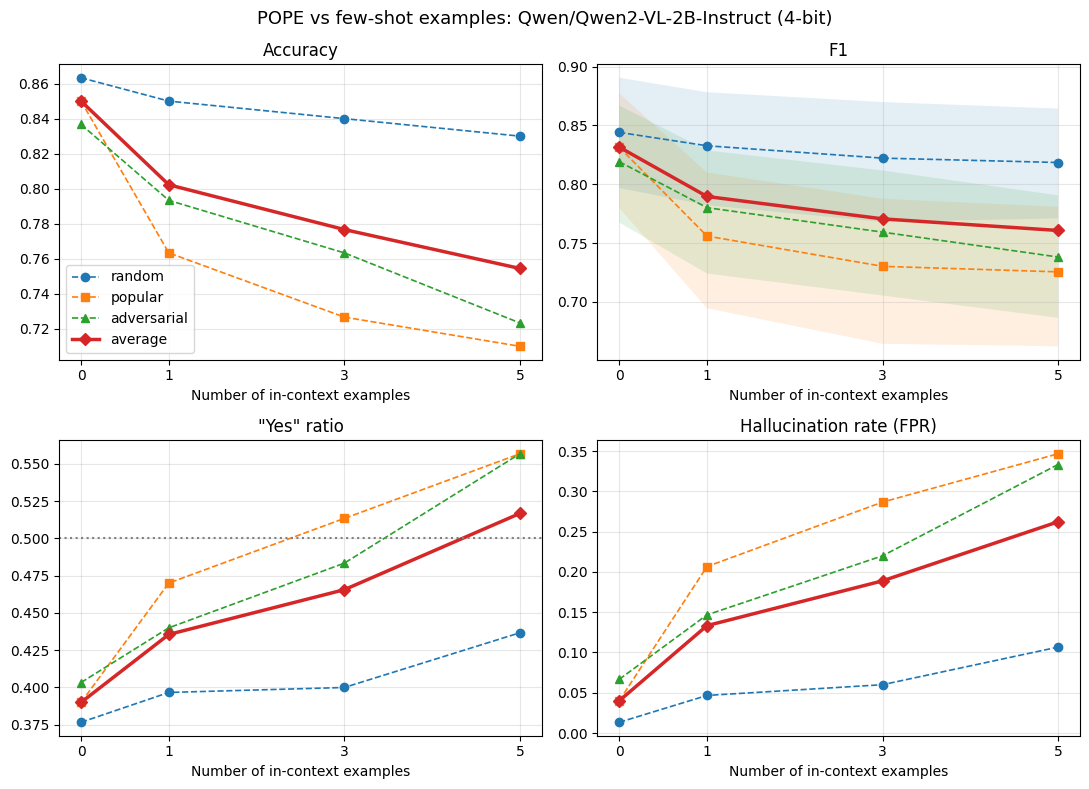

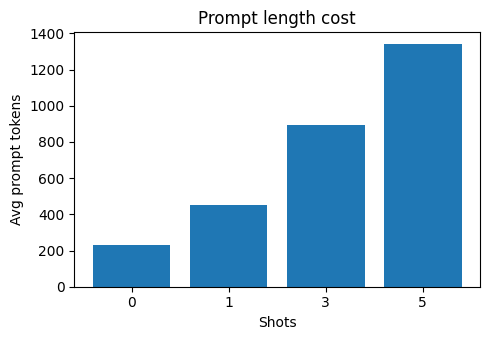

In [15]:
import matplotlib.pyplot as plt

panels = [("accuracy", "Accuracy"), ("f1", "F1"), ("yes_ratio", '"Yes" ratio'), ("halluc_rate", "Hallucination rate (FPR)")]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (col, title) in zip(axes.ravel(), panels):
    for cat, style in zip(CATEGORIES + ["average"], ["o--", "s--", "^--", "D-"]):
        d = table_all[table_all["category"] == cat].sort_values("shot")
        ax.plot(d["shot"], d[col], style, label=cat, linewidth=2.5 if cat == "average" else 1.2)
        if col == "f1" and cat != "average":
            ax.fill_between(d["shot"], d["f1_lo"], d["f1_hi"], alpha=0.12)  # bootstrap 95% CI band
    if col == "yes_ratio":
        ax.axhline(0.5, color="gray", linestyle=":", label="ideal (0.5)")  # balanced dataset reference
    ax.set_xticks(SHOTS); ax.set_xlabel("Number of in-context examples"); ax.set_title(title); ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle(f"POPE vs few-shot examples: {CFG['hf_id']} (4-bit)", fontsize=13)
fig.tight_layout()
FIG_PATH = os.path.join(FIG_DIR, f"pope_fewshot_{MODEL_NAME}.png")
fig.savefig(FIG_PATH, dpi=200)  # saved to Drive
plt.show()

# Second plot: prompt length grows with shots (the cost side of few-shot prompting)
fig2, ax2 = plt.subplots(figsize=(5, 3.5))
d = table_all[table_all["category"] == "average"].sort_values("shot")
ax2.bar(d["shot"].astype(str), d["avg_tokens"])
ax2.set_xlabel("Shots"); ax2.set_ylabel("Avg prompt tokens"); ax2.set_title("Prompt length cost")
fig2.tight_layout()
COST_PATH = os.path.join(FIG_DIR, f"prompt_tokens_{MODEL_NAME}.png")
fig2.savefig(COST_PATH, dpi=200)
plt.show()

## 13. Short report (written to Drive as `report.md`)

In [16]:
a = table_all[table_all["category"] == "average"].set_index("shot")
best_k = a["f1"].idxmax()  # shot count with the highest mean F1
d_f1 = a.loc[best_k, "f1"] - a.loc[0, "f1"]
d_h = a.loc[best_k, "halluc_rate"] - a.loc[0, "halluc_rate"]
sig = mcnemar[(mcnemar["shot"] == best_k) & (mcnemar["p_value"] < 0.05)]["category"].tolist() if len(mcnemar) else []

def fmt_table(df):
    # Convert the metrics table to a markdown table
    cols = ["category", "shot", "accuracy", "f1", "precision", "recall", "yes_ratio", "halluc_rate", "auroc"]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.sort_values(["category", "shot"]).iterrows():
        lines.append("| " + " | ".join(str(r[c]) if c in ("category", "shot") else f"{r[c]:.3f}" for c in cols) + " |")
    return "\n".join(lines)

report = f'''# Few-shot prompting and object hallucination in a small VLM

## Question
Does adding in-context examples (0, 1, 3, 5) reduce object hallucination of a small vision-language model on POPE?

## Setup
- Model: {CFG["hf_id"]}, 4-bit NF4 (bitsandbytes), vision encoder kept in 16-bit, single T4 GPU.
- Data: POPE COCO, {len(eval_df)} balanced questions ({N_PER_CATEGORY} per split: random, popular, adversarial).
- Demos: drawn from {N_DEMO_IMAGES} held-out COCO images of the same split, balanced yes/no, never overlapping with test images.
- Scoring: next-token probability of Yes vs No, prediction = Yes if P(yes) >= 0.5.
- Metrics: accuracy, precision, recall, F1, yes ratio, hallucination rate (false positive rate), AUROC; 95% bootstrap CI for F1; exact McNemar test against 0-shot.

## Results
{fmt_table(table_all)}

![metrics](figures/{os.path.basename(FIG_PATH)})

## Findings
- Mean F1 goes from {a.loc[0, "f1"]:.3f} at 0-shot to {a.loc[best_k, "f1"]:.3f} at {best_k}-shot (change {d_f1:+.3f}).
- Hallucination rate changes from {a.loc[0, "halluc_rate"]:.3f} to {a.loc[best_k, "halluc_rate"]:.3f} ({d_h:+.3f}); yes ratio moves from {a.loc[0, "yes_ratio"]:.3f} to {a.loc[best_k, "yes_ratio"]:.3f}.
- AUROC moves from {a.loc[0, "auroc"]:.3f} to {a.loc[best_k, "auroc"]:.3f}. If AUROC stays flat while yes ratio shifts, the examples mainly change the answer bias, not the model's actual visual grounding.
- McNemar p < 0.05 for {best_k}-shot vs 0-shot on: {", ".join(sig) if sig else "no split"}.
- Cost: average prompt length grows from {a.loc[0, "avg_tokens"]:.0f} to {a.loc[max(SHOTS), "avg_tokens"]:.0f} tokens at {max(SHOTS)}-shot.

## Limitations
Subset of POPE ({N_PER_CATEGORY} per split), one demo-sampling seed, one prompt template, 4-bit weights. Results should be confirmed with more seeds and the full benchmark.
'''
with open(os.path.join(BASE_DIR, "report.md"), "w") as f:
    f.write(report)
print(report)

# Few-shot prompting and object hallucination in a small VLM

## Question
Does adding in-context examples (0, 1, 3, 5) reduce object hallucination of a small vision-language model on POPE?

## Setup
- Model: Qwen/Qwen2-VL-2B-Instruct, 4-bit NF4 (bitsandbytes), vision encoder kept in 16-bit, single T4 GPU.
- Data: POPE COCO, 900 balanced questions (300 per split: random, popular, adversarial).
- Demos: drawn from 10 held-out COCO images of the same split, balanced yes/no, never overlapping with test images.
- Scoring: next-token probability of Yes vs No, prediction = Yes if P(yes) >= 0.5.
- Metrics: accuracy, precision, recall, F1, yes ratio, hallucination rate (false positive rate), AUROC; 95% bootstrap CI for F1; exact McNemar test against 0-shot.

## Results
| category | shot | accuracy | f1 | precision | recall | yes_ratio | halluc_rate | auroc |
|---|---|---|---|---|---|---|---|---|
| adversarial | 0 | 0.837 | 0.819 | 0.917 | 0.740 | 0.403 | 0.067 | 0.927 |
| adversarial | 1 | 0.79

###Train Model for Smolvlm

In [17]:
import os  # file paths and environment variables
import sys  # used to detect whether we are on Colab

# Reduce GPU memory fragmentation; must be set BEFORE torch is imported
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# Hide a harmless tokenizers warning that appears when using multiple workers
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ---------------- Experiment settings ----------------
MODEL_NAME = "smolvlm"          # "qwen2-vl-2b" or "smolvlm"
SHOTS = [0, 1, 3, 5]                # numbers of in-context examples to test
CATEGORIES = ["random", "popular", "adversarial"]  # the three POPE splits
N_PER_CATEGORY = 300                # questions per split (max ~2940); 300 x 3 x 4 = 3600 forward passes
N_DEMO_IMAGES = 10                  # COCO images reserved ONLY for few-shot examples (never evaluated)
SEED = 42                           # global random seed for reproducibility

# ---------------- Memory settings ----------------
MAX_IMAGE_SIDE = 448                # images are shrunk so the longest side is at most this many pixels
QWEN_MIN_PIXELS = 128 * 28 * 28     # Qwen2-VL: lower bound on image area (controls visual tokens)
QWEN_MAX_PIXELS = 256 * 28 * 28     # Qwen2-VL: upper bound, about 256 visual tokens per image
CLEANUP_EVERY = 50                  # free cached GPU memory every N questions
SAVE_EVERY = 20                     # write results to Drive every N questions

# ---------------- Storage settings ----------------
CACHE_MODEL_IN_DRIVE = False        # True = keep a copy of the ~4.5 GB model in Drive (saves download time, costs Drive space)
PROJECT_FOLDER = "VLM_FewShot_POPE" # folder name inside your Drive

# Registry of supported models: HF repo id and modules that should NOT be quantized
MODEL_REGISTRY = {
    "qwen2-vl-2b": {
        "hf_id": "Qwen/Qwen2-VL-2B-Instruct",
        "skip_modules": ["visual", "lm_head"],  # keep vision encoder and output head in 16-bit for quality
    },
    "smolvlm": {
        "hf_id": "HuggingFaceTB/SmolVLM-Instruct",
        "skip_modules": ["vision_model", "connector", "lm_head"],  # same idea for SmolVLM
    },
}
assert MODEL_NAME in MODEL_REGISTRY, f"MODEL_NAME must be one of {list(MODEL_REGISTRY)}"
CFG = MODEL_REGISTRY[MODEL_NAME]  # settings of the chosen model

In [18]:
# Detect the platform so the same notebook works on Colab, Kaggle or a local machine
try:
    from google.colab import drive  # only importable on Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_KAGGLE = os.path.exists("/kaggle/working")  # Kaggle always has this folder

if IN_COLAB:
    drive.mount("/content/drive")  # ask for Drive permission and mount it
    BASE_DIR = f"/content/drive/MyDrive/{PROJECT_FOLDER}"  # results survive session resets here
    LOCAL_DIR = "/content"  # fast local disk for temporary caches
elif IN_KAGGLE:
    BASE_DIR = f"/kaggle/working/{PROJECT_FOLDER}"  # saved when you "Save Version" on Kaggle
    LOCAL_DIR = "/kaggle/temp"
else:
    BASE_DIR = os.path.abspath(PROJECT_FOLDER)
    LOCAL_DIR = os.path.abspath(".cache_local")

FIG_DIR = os.path.join(BASE_DIR, "figures")  # plots go here
DATA_CACHE = os.path.join(LOCAL_DIR, "hf_datasets")  # dataset cache (local, re-downloaded each session)
# Model cache: Drive if requested, otherwise local disk
MODEL_CACHE = os.path.join(BASE_DIR, "hf_models") if CACHE_MODEL_IN_DRIVE else os.path.join(LOCAL_DIR, "hf_models")
for d in [BASE_DIR, FIG_DIR, DATA_CACHE, MODEL_CACHE]:
    os.makedirs(d, exist_ok=True)  # create folder if it does not exist

# Files that make resuming possible
EVAL_SET_PATH = os.path.join(BASE_DIR, "eval_set.csv")  # fixed list of evaluation questions
DEMO_SET_PATH = os.path.join(BASE_DIR, "demo_set.csv")  # fixed pool of few-shot examples
RESULTS_PATH = os.path.join(BASE_DIR, f"results_{MODEL_NAME}.jsonl")  # one line per answered question
ERRORS_PATH = os.path.join(BASE_DIR, f"errors_{MODEL_NAME}.jsonl")  # questions that failed (retried next run)
print("Saving everything to:", BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving everything to: /content/drive/MyDrive/VLM_FewShot_POPE


In [19]:
import gc  # manual garbage collection to free RAM
import json  # results are stored as JSON lines
import math  # small math helpers
import time  # timing
import random  # deterministic demo sampling
import inspect  # check which arguments the model forward accepts
import numpy as np  # numeric arrays
import pandas as pd  # tables
import torch  # deep learning framework
from tqdm.auto import tqdm  # progress bars

random.seed(SEED)  # Python RNG
np.random.seed(SEED)  # NumPy RNG
torch.manual_seed(SEED)  # PyTorch RNG

assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > T4 GPU"
DEVICE = torch.device("cuda:0")  # we use exactly one GPU
major, _ = torch.cuda.get_device_capability(0)  # T4 = 7.x, A100 = 8.x
# T4 has no real bfloat16 support, so use float16 there; newer GPUs use bfloat16
COMPUTE_DTYPE = torch.bfloat16 if major >= 8 else torch.float16
print("GPU:", torch.cuda.get_device_name(0), "| compute dtype:", COMPUTE_DTYPE)
print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

def gpu_mem():
    # Return a short string with currently allocated and reserved GPU memory
    return f"alloc {torch.cuda.memory_allocated() / 1e9:.2f} GB | reserved {torch.cuda.memory_reserved() / 1e9:.2f} GB"

def cleanup():
    # Free Python objects and cached GPU blocks
    gc.collect()
    torch.cuda.empty_cache()

GPU: Tesla T4 | compute dtype: torch.float16
GPU memory: 15.6 GB


In [20]:
from datasets import load_dataset  # Hugging Face datasets library

# lmms-lab/POPE: 9000 COCO questions (3000 per split), images are embedded in the dataset
pope = load_dataset("lmms-lab/POPE", split="test", cache_dir=DATA_CACHE)
print(pope)

# Read ONLY the text columns into pandas; images stay on disk and are decoded one at a time later
meta = pope.select_columns(["question_id", "question", "answer", "image_source", "category"]).to_pandas()
meta["row_idx"] = np.arange(len(meta))  # remember the original row to fetch the image later
meta["answer"] = meta["answer"].str.strip().str.lower()  # normalise labels to "yes" / "no"
meta["category"] = meta["category"].str.strip().str.lower()  # normalise split names
meta["question_id"] = meta["question_id"].astype(str)  # string ids are safer as dict keys
print(meta.groupby(["category", "answer"]).size())

Dataset({
    features: ['id', 'question_id', 'question', 'answer', 'image_source', 'image', 'category'],
    num_rows: 9000
})
category     answer
adversarial  no        1500
             yes       1500
popular      no        1500
             yes       1500
random       no        1500
             yes       1500
dtype: int64


In [21]:
def load_image(row_idx, max_side=MAX_IMAGE_SIDE):
    # Decode a single image from the dataset, convert to RGB and shrink it in place
    img = pope[int(row_idx)]["image"].convert("RGB")
    img.thumbnail((max_side, max_side))  # keeps aspect ratio, never upsizes
    return img

# Cache demo images in RAM: only N_DEMO_IMAGES small images, so this is cheap
DEMO_IMG_CACHE = {}
def demo_image(image_source, row_idx):
    if image_source not in DEMO_IMG_CACHE:
        DEMO_IMG_CACHE[image_source] = load_image(row_idx)
    return DEMO_IMG_CACHE[image_source]

def pick_demos(k, category, qid):
    # Choose k demos from the same POPE split, balanced between "yes" and "no".
    # The RNG is seeded by (category, question, k) so a resumed run picks the same demos.
    if k == 0:
        return []
    r = random.Random(f"{SEED}-{category}-{qid}-{k}")
    pool = demo_df[demo_df["category"] == category]
    yes_pool = pool[pool["answer"] == "yes"].to_dict("records")
    no_pool = pool[pool["answer"] == "no"].to_dict("records")
    n_yes = k // 2 + (r.randint(0, 1) if k % 2 else 0)  # odd k: the extra example is yes or no at random
    picks = r.sample(yes_pool, n_yes) + r.sample(no_pool, k - n_yes)
    r.shuffle(picks)  # random order so the last demo label is not always the same
    return picks

INSTRUCTION = "Answer the question with a single word: Yes or No."

def user_turn(question):
    # One user message = one image placeholder + the question text
    return {"role": "user", "content": [{"type": "image"}, {"type": "text", "text": f"{question} {INSTRUCTION}"}]}

def build_conversation(demos, question, query_img):
    # Few-shot examples are given as previous turns of the chat, each answered correctly
    messages, images = [], []
    for d in demos:
        messages.append(user_turn(d["question"]))
        messages.append({"role": "assistant", "content": [{"type": "text", "text": "Yes" if d["answer"] == "yes" else "No"}]})
        images.append(demo_image(d["image_source"], d["row_idx"]))
    messages.append(user_turn(question))  # the real test question comes last
    images.append(query_img)
    return messages, images  # images are in the same order as the image placeholders

In [25]:
from transformers import AutoProcessor, BitsAndBytesConfig

# NF4 4-bit quantization with double quantization: the smallest memory footprint bitsandbytes offers
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,                      # store linear-layer weights in 4 bits
    bnb_4bit_quant_type="nf4",              # NormalFloat4, best quality for 4-bit
    bnb_4bit_use_double_quant=True,         # also quantize the quantization constants (saves ~0.4 bit/param)
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,   # matmuls run in fp16 on T4
    llm_int8_skip_modules=CFG["skip_modules"],  # keep vision tower and lm_head unquantized
)

# FIX: Correct the model class loading logic for smolvlm and qwen2-vl-2b
if MODEL_NAME == "qwen2-vl-2b":
    from transformers import Qwen2VLForConditionalGeneration as ModelCls
    # min/max_pixels cap the number of visual tokens per image (main memory knob for Qwen2-VL)
    processor = AutoProcessor.from_pretrained(CFG["hf_id"], min_pixels=QWEN_MIN_PIXELS,
                                              max_pixels=QWEN_MAX_PIXELS, cache_dir=MODEL_CACHE)
else: # smolvlm
    try:
        from transformers import AutoModelForImageTextToText as ModelCls  # newer transformers
    except ImportError:
        from transformers import AutoModelForVision2Seq as ModelCls  # older transformers
    processor = AutoProcessor.from_pretrained(CFG["hf_id"], cache_dir=MODEL_CACHE)
    # SmolVLM normally cuts every image into many tiles; disabling it keeps ~81 tokens per image
    processor.image_processor.do_image_splitting = False

model = ModelCls.from_pretrained(
    CFG["hf_id"],
    quantization_config=bnb_config,  # apply 4-bit quantization while loading
    torch_dtype=COMPUTE_DTYPE,       # non-quantized parts in fp16
    device_map={"": 0},              # put the whole model on GPU 0
    low_cpu_mem_usage=True,          # stream weights so system RAM does not spike
    attn_implementation="sdpa",      # memory-efficient attention available on T4
    cache_dir=MODEL_CACHE,
)
model.eval()  # inference mode: disables dropout
tokenizer = processor.tokenizer  # text tokenizer inside the processor
cleanup()
print("Model loaded |", gpu_mem())
print(f"Model memory footprint: {model.get_memory_footprint() / 1e9:.2f} GB")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

Model loaded | alloc 6.45 GB | reserved 6.49 GB
Model memory footprint: 1.43 GB


In [28]:
def first_token_ids(words):
    # Token id of the first sub-token of each spelling variant
    ids = set()
    for w in words:
        t = tokenizer.encode(w, add_special_tokens=False)
        if t:
            ids.add(t[0])
    return sorted(ids)

YES_IDS = first_token_ids(["Yes", "yes", " Yes", " yes", "YES"])
NO_IDS = first_token_ids(["No", "no", " No", " no", "NO"])
assert not set(YES_IDS) & set(NO_IDS), "Yes/No token ids overlap"
print("Yes ids:", YES_IDS, "| No ids:", NO_IDS)

FWD_PARAMS = inspect.signature(model.forward).parameters
if "logits_to_keep" in FWD_PARAMS:
    LOGIT_KW = {"logits_to_keep": 1}
elif "num_logits_to_keep" in FWD_PARAMS:
    LOGIT_KW = {"num_logits_to_keep": 1}
else:
    LOGIT_KW = {}
print("Extra forward kwargs:", LOGIT_KW)

def prepare_inputs(messages, images):
    # Turn the chat into the model's prompt text, then tokenize text + images together
    text = processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)

    # For SmolVLM, the processor expects images to be passed in a list inside a list if there are multiple turns
    # processor handles the mapping of placeholders dynamically
    inputs = processor(text=[text], images=[images], return_tensors="pt").to(DEVICE)
    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(COMPUTE_DTYPE)
    return inputs

@torch.inference_mode()
def score_yes_no(messages, images):
    inputs = prepare_inputs(messages, images)
    n_tokens = int(inputs["input_ids"].shape[1])
    out = model(**inputs, use_cache=False, **LOGIT_KW)
    logits = out.logits[0, -1].float()
    del out, inputs
    if not torch.isfinite(logits).all():
        raise FloatingPointError("Non-finite logits (fp16 overflow)")
    logp = torch.log_softmax(logits, dim=-1)
    lp_yes = torch.logsumexp(logp[YES_IDS], dim=0)
    lp_no = torch.logsumexp(logp[NO_IDS], dim=0)
    p_yes = torch.sigmoid(lp_yes - lp_no).item()
    mass = (lp_yes.exp() + lp_no.exp()).item()
    return p_yes, mass, n_tokens

@torch.inference_mode()
def generate_text(messages, images, max_new_tokens=5):
    inputs = prepare_inputs(messages, images)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    text = processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0]
    del out, inputs
    return text.strip()

Yes ids: [73, 9230, 9805, 10407, 10539] | No ids: [787, 2838, 4607, 5230, 13465]
Extra forward kwargs: {'logits_to_keep': 1}


In [27]:
for _, row in eval_df.head(3).iterrows():
    img = load_image(row["row_idx"])
    for k in [0, 3]:
        msgs, imgs = build_conversation(pick_demos(k, row["category"], row["question_id"]), row["question"], img)
        p, mass, n = score_yes_no(msgs, imgs)
        gen = generate_text(msgs, imgs)
        print(f"[{k}-shot] {row['question'][:60]:60s} | label={row['answer']:3s} | P(yes)={p:.3f} "
              f"| yes/no mass={mass:.2f} | gen='{gen}' | tokens={n}")
    del img
cleanup()
print(gpu_mem())

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[0-shot] Is there a zebra in the image?                               | label=yes | P(yes)=0.939 | yes/no mass=1.00 | gen='Yes.' | tokens=116
[3-shot] Is there a zebra in the image?                               | label=yes | P(yes)=0.665 | yes/no mass=1.00 | gen='Yes.' | tokens=471


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[0-shot] Is there a car in the image?                                 | label=no  | P(yes)=0.001 | yes/no mass=1.00 | gen='No.' | tokens=116
[3-shot] Is there a car in the image?                                 | label=no  | P(yes)=0.001 | yes/no mass=1.00 | gen='No' | tokens=470


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[0-shot] Is there a cow in the image?                                 | label=no  | P(yes)=0.001 | yes/no mass=1.00 | gen='No.' | tokens=116
[3-shot] Is there a cow in the image?                                 | label=no  | P(yes)=0.000 | yes/no mass=1.00 | gen='No.' | tokens=470
alloc 6.45 GB | reserved 6.49 GB


In [29]:
def read_jsonl(path):
    # Read a JSON-lines file; silently skip a half-written last line from a crashed session
    rows = []
    if os.path.exists(path):
        with open(path) as f:
            for line in f:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    pass
    return rows

def append_jsonl(path, rows):
    # Append rows and force them to disk so nothing is lost if the runtime disconnects
    if not rows:
        return
    with open(path, "a") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
        f.flush()
        os.fsync(f.fileno())

def key(shot, cat, qid):
    return f"{shot}|{cat}|{qid}"  # unique id of one (setting, question) job

done = {key(r["shot"], r["category"], r["question_id"]) for r in read_jsonl(RESULTS_PATH)}  # already answered
jobs = [(k, r) for k in SHOTS for r in eval_df.to_dict("records")
        if key(k, r["category"], r["question_id"]) not in done]  # what is still left
total = len(SHOTS) * len(eval_df)
print(f"Done: {len(done)} / {total} | remaining: {len(jobs)}")

Done: 0 / 3600 | remaining: 3600


In [30]:
buffer, errors = [], []  # results waiting to be written, and failures
t0 = time.time()
for i, (k, row) in enumerate(tqdm(jobs, desc=f"{MODEL_NAME} POPE")):
    demos = pick_demos(k, row["category"], row["question_id"])  # deterministic few-shot examples
    result = None
    for attempt, side in enumerate([MAX_IMAGE_SIDE, MAX_IMAGE_SIDE // 2]):  # retry once with smaller images on OOM
        try:
            img = load_image(row["row_idx"], side)
            msgs, imgs = build_conversation(demos, row["question"], img)
            if side != MAX_IMAGE_SIDE:
                imgs = [im.copy() for im in imgs]  # do not shrink the cached demo images themselves
                for im in imgs:
                    im.thumbnail((side, side))
            p_yes, mass, n_tok = score_yes_no(msgs, imgs)
            result = {
                "model": MODEL_NAME, "shot": k, "category": row["category"],
                "question_id": row["question_id"], "label": row["answer"],
                "p_yes": round(p_yes, 6), "pred": "yes" if p_yes >= 0.5 else "no",
                "yes_no_mass": round(mass, 4), "n_tokens": n_tok,
                "demo_labels": "".join(d["answer"][0] for d in demos),  # e.g. "yny"
            }
            break
        except (torch.cuda.OutOfMemoryError, FloatingPointError) as e:
            cleanup()  # free memory before the retry
            err = repr(e)[:200]
        finally:
            img = imgs = msgs = None  # drop references so memory can be reclaimed
    if result is None:
        errors.append({"shot": k, "category": row["category"], "question_id": row["question_id"], "error": err})
    else:
        buffer.append(result)

    if len(buffer) >= SAVE_EVERY:  # periodic checkpoint to Drive
        append_jsonl(RESULTS_PATH, buffer); buffer = []
        append_jsonl(ERRORS_PATH, errors); errors = []
    if (i + 1) % CLEANUP_EVERY == 0:  # periodic memory cleanup
        cleanup()
        tqdm.write(f"{i + 1} done | {gpu_mem()} | {(time.time() - t0) / (i + 1):.2f} s/question")

append_jsonl(RESULTS_PATH, buffer)  # write whatever is left
append_jsonl(ERRORS_PATH, errors)
cleanup()
print("Evaluation finished. Errors this run:", len(errors))

smolvlm POPE:   0%|          | 0/3600 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


50 done | alloc 6.45 GB | reserved 6.49 GB | 0.27 s/question
100 done | alloc 6.45 GB | reserved 6.49 GB | 0.23 s/question
150 done | alloc 6.45 GB | reserved 6.49 GB | 0.22 s/question
200 done | alloc 6.45 GB | reserved 6.49 GB | 0.22 s/question
250 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
300 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
350 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
400 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
450 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
500 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
550 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
600 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
650 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
700 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
750 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
800 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question
850 done 

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with b

950 done | alloc 6.45 GB | reserved 6.49 GB | 0.21 s/question


...

1700 done | alloc 6.45 GB | reserved 6.49 GB | 0.28 s/question


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with b

1750 done | alloc 6.45 GB | reserved 6.49 GB | 0.28 s/question


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with b

1800 done | alloc 6.45 GB | reserved 6.49 GB | 0.28 s/question
1850 done | alloc 6.45 GB | reserved 6.49 GB | 0.29 s/question
1900 done | alloc 6.45 GB | reserved 6.49 GB | 0.30 s/question
1950 done | alloc 6.45 GB | reserved 6.49 GB | 0.31 s/question
2000 done | alloc 6.45 GB | reserved 6.49 GB | 0.32 s/question
2050 done | alloc 6.45 GB | reserved 6.49 GB | 0.32 s/question
2100 done | alloc 6.45 GB | reserved 6.49 GB | 0.33 s/question
2150 done | alloc 6.45 GB | reserved 6.49 GB | 0.34 s/question
2200 done | alloc 6.45 GB | reserved 6.49 GB | 0.35 s/question
2250 done | alloc 6.45 GB | reserved 6.49 GB | 0.35 s/question
2300 done | alloc 6.45 GB | reserved 6.49 GB | 0.36 s/question
2350 done | alloc 6.45 GB | reserved 6.49 GB | 0.37 s/question
2400 done | alloc 6.45 GB | reserved 6.49 GB | 0.37 s/question
2450 done | alloc 6.45 GB | reserved 6.49 GB | 0.38 s/question
2500 done | alloc 6.45 GB | reserved 6.49 GB | 0.38 s/question
2550 done | alloc 6.45 GB | reserved 6.49 GB | 0.39 s/q

In [31]:
from sklearn.metrics import roc_auc_score
from scipy.stats import binomtest

res = pd.DataFrame(read_jsonl(RESULTS_PATH))  # all answers collected so far (across sessions)
res = res.drop_duplicates(subset=["shot", "category", "question_id"], keep="last")  # safety against duplicates
print("Rows:", len(res), "| expected:", total)

def basic_metrics(y_true, y_pred):
    # y_true, y_pred: boolean arrays where True means "yes"
    tp = np.sum(y_true & y_pred); tn = np.sum(~y_true & ~y_pred)
    fp = np.sum(~y_true & y_pred); fn = np.sum(y_true & ~y_pred)
    n = len(y_true)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {
        "accuracy": (tp + tn) / n, "precision": prec, "recall": rec, "f1": f1,
        "yes_ratio": y_pred.mean(),  # share of "yes" answers (0.5 is ideal on balanced POPE)
        "halluc_rate": fp / (fp + tn) if fp + tn else 0.0,  # says "yes" to an absent object
    }

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=SEED):
    # 95% percentile bootstrap confidence interval of one metric
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y_true), size=(n_boot, len(y_true)))
    vals = [basic_metrics(y_true[j], y_pred[j])[metric] for j in idx]
    return np.percentile(vals, [2.5, 97.5])

rows = []
for (k, cat), g in res.groupby(["shot", "category"]):
    yt = (g["label"] == "yes").values; yp = (g["pred"] == "yes").values
    m = basic_metrics(yt, yp)
    m["auroc"] = roc_auc_score(yt, g["p_yes"]) if len(set(yt)) == 2 else np.nan  # threshold-free separability
    m["f1_lo"], m["f1_hi"] = bootstrap_ci(yt, yp, "f1")
    m.update({"shot": k, "category": cat, "n": len(g), "avg_tokens": g["n_tokens"].mean()})
    rows.append(m)
table = pd.DataFrame(rows)

# Average over the three splits (this is the usual POPE headline number)
avg = table.groupby("shot")[["accuracy", "precision", "recall", "f1", "yes_ratio", "halluc_rate", "auroc", "avg_tokens"]].mean().reset_index()
avg["category"] = "average"
table_all = pd.concat([table, avg], ignore_index=True)
table_all.to_csv(os.path.join(BASE_DIR, f"metrics_{MODEL_NAME}.csv"), index=False)  # save table to Drive
pd.set_option("display.float_format", "{:.3f}".format)
display(table_all[["category", "shot", "n", "accuracy", "f1", "f1_lo", "f1_hi", "precision", "recall",
                   "yes_ratio", "halluc_rate", "auroc", "avg_tokens"]].sort_values(["category", "shot"]))

Rows: 3600 | expected: 3600


,category,shot,n,accuracy,f1,f1_lo,f1_hi,precision,recall,yes_ratio,halluc_rate,auroc,avg_tokens
0,adversarial,0,300.000,0.787,0.750,0.691,0.807,0.906,0.640,0.353,0.067,0.880,116.303
3,adversarial,1,300.000,0.727,0.655,0.585,0.723,0.886,0.520,0.293,0.067,0.870,234.493
6,adversarial,3,300.000,0.750,0.686,0.620,0.748,0.921,0.547,0.297,0.047,0.882,470.793
9,adversarial,5,300.000,0.733,0.661,0.589,0.726,0.907,0.520,0.287,0.053,0.877,707.137
12,average,0,NaN,0.802,0.764,NaN,NaN,0.949,0.640,0.338,0.036,0.917,116.298
13,average,1,NaN,0.740,0.670,NaN,NaN,0.919,0.527,0.287,0.047,0.896,234.459
14,average,3,NaN,0.751,0.681,NaN,NaN,0.949,0.531,0.280,0.029,0.910,470.764
15,average,5,NaN,0.744,0.674,NaN,NaN,0.930,0.529,0.284,0.040,0.903,707.037
1,popular,0,300.000,0.803,0.765,0.705,0.823,0.950,0.640,0.337,0.033,0.924,116.247
4,popular,1,300.000,0.740,0.669,0.598,0.740,0.919,0.527,0.287,0.047,0.883,234.417


In [32]:
# McNemar exact test: is k-shot accuracy different from 0-shot on the SAME questions?
mc_rows = []
for cat in CATEGORIES:
    base = res[(res["shot"] == 0) & (res["category"] == cat)].set_index("question_id")
    for k in [s for s in SHOTS if s != 0]:
        cur = res[(res["shot"] == k) & (res["category"] == cat)].set_index("question_id")
        common = base.index.intersection(cur.index)  # paired questions only
        if len(common) == 0:
            continue
        c0 = (base.loc[common, "pred"] == base.loc[common, "label"]).values  # 0-shot correct?
        ck = (cur.loc[common, "pred"] == cur.loc[common, "label"]).values  # k-shot correct?
        b = int(np.sum(c0 & ~ck)); c = int(np.sum(~c0 & ck))  # discordant pairs
        p = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
        mc_rows.append({"category": cat, "shot": k, "0shot_only_correct": b, "kshot_only_correct": c, "p_value": p})
mcnemar = pd.DataFrame(mc_rows)
mcnemar.to_csv(os.path.join(BASE_DIR, f"mcnemar_{MODEL_NAME}.csv"), index=False)
display(mcnemar)

,category,shot,0shot_only_correct,kshot_only_correct,p_value
0,random,1,26,7,0.001
1,random,3,27,9,0.004
2,random,5,34,12,0.002
3,popular,1,27,8,0.002
4,popular,3,29,12,0.012
5,popular,5,28,14,0.044
6,adversarial,1,25,7,0.002
7,adversarial,3,26,15,0.117
8,adversarial,5,30,14,0.023


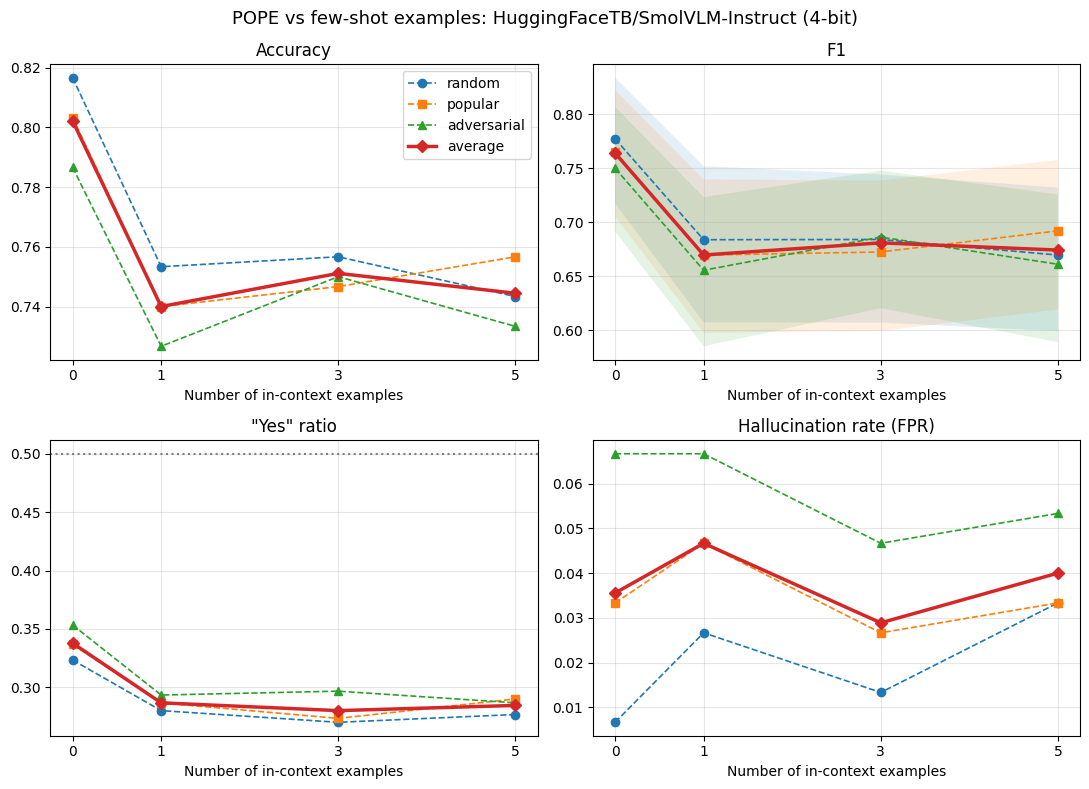

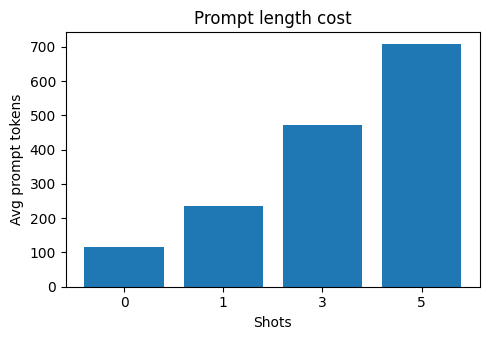

In [33]:
import matplotlib.pyplot as plt

panels = [("accuracy", "Accuracy"), ("f1", "F1"), ("yes_ratio", '"Yes" ratio'), ("halluc_rate", "Hallucination rate (FPR)")]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (col, title) in zip(axes.ravel(), panels):
    for cat, style in zip(CATEGORIES + ["average"], ["o--", "s--", "^--", "D-"]):
        d = table_all[table_all["category"] == cat].sort_values("shot")
        ax.plot(d["shot"], d[col], style, label=cat, linewidth=2.5 if cat == "average" else 1.2)
        if col == "f1" and cat != "average":
            ax.fill_between(d["shot"], d["f1_lo"], d["f1_hi"], alpha=0.12)  # bootstrap 95% CI band
    if col == "yes_ratio":
        ax.axhline(0.5, color="gray", linestyle=":", label="ideal (0.5)")  # balanced dataset reference
    ax.set_xticks(SHOTS); ax.set_xlabel("Number of in-context examples"); ax.set_title(title); ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle(f"POPE vs few-shot examples: {CFG['hf_id']} (4-bit)", fontsize=13)
fig.tight_layout()
FIG_PATH = os.path.join(FIG_DIR, f"pope_fewshot_{MODEL_NAME}.png")
fig.savefig(FIG_PATH, dpi=200)  # saved to Drive
plt.show()

# Second plot: prompt length grows with shots (the cost side of few-shot prompting)
fig2, ax2 = plt.subplots(figsize=(5, 3.5))
d = table_all[table_all["category"] == "average"].sort_values("shot")
ax2.bar(d["shot"].astype(str), d["avg_tokens"])
ax2.set_xlabel("Shots"); ax2.set_ylabel("Avg prompt tokens"); ax2.set_title("Prompt length cost")
fig2.tight_layout()
COST_PATH = os.path.join(FIG_DIR, f"prompt_tokens_{MODEL_NAME}.png")
fig2.savefig(COST_PATH, dpi=200)
plt.show()

In [34]:
a = table_all[table_all["category"] == "average"].set_index("shot")
best_k = a["f1"].idxmax()  # shot count with the highest mean F1
d_f1 = a.loc[best_k, "f1"] - a.loc[0, "f1"]
d_h = a.loc[best_k, "halluc_rate"] - a.loc[0, "halluc_rate"]
sig = mcnemar[(mcnemar["shot"] == best_k) & (mcnemar["p_value"] < 0.05)]["category"].tolist() if len(mcnemar) else []

def fmt_table(df):
    # Convert the metrics table to a markdown table
    cols = ["category", "shot", "accuracy", "f1", "precision", "recall", "yes_ratio", "halluc_rate", "auroc"]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.sort_values(["category", "shot"]).iterrows():
        lines.append("| " + " | ".join(str(r[c]) if c in ("category", "shot") else f"{r[c]:.3f}" for c in cols) + " |")
    return "\n".join(lines)

report = f'''# Few-shot prompting and object hallucination in a small VLM

## Question
Does adding in-context examples (0, 1, 3, 5) reduce object hallucination of a small vision-language model on POPE?

## Setup
- Model: {CFG["hf_id"]}, 4-bit NF4 (bitsandbytes), vision encoder kept in 16-bit, single T4 GPU.
- Data: POPE COCO, {len(eval_df)} balanced questions ({N_PER_CATEGORY} per split: random, popular, adversarial).
- Demos: drawn from {N_DEMO_IMAGES} held-out COCO images of the same split, balanced yes/no, never overlapping with test images.
- Scoring: next-token probability of Yes vs No, prediction = Yes if P(yes) >= 0.5.
- Metrics: accuracy, precision, recall, F1, yes ratio, hallucination rate (false positive rate), AUROC; 95% bootstrap CI for F1; exact McNemar test against 0-shot.

## Results
{fmt_table(table_all)}

![metrics](figures/{os.path.basename(FIG_PATH)})

## Findings
- Mean F1 goes from {a.loc[0, "f1"]:.3f} at 0-shot to {a.loc[best_k, "f1"]:.3f} at {best_k}-shot (change {d_f1:+.3f}).
- Hallucination rate changes from {a.loc[0, "halluc_rate"]:.3f} to {a.loc[best_k, "halluc_rate"]:.3f} ({d_h:+.3f}); yes ratio moves from {a.loc[0, "yes_ratio"]:.3f} to {a.loc[best_k, "yes_ratio"]:.3f}.
- AUROC moves from {a.loc[0, "auroc"]:.3f} to {a.loc[best_k, "auroc"]:.3f}. If AUROC stays flat while yes ratio shifts, the examples mainly change the answer bias, not the model's actual visual grounding.
- McNemar p < 0.05 for {best_k}-shot vs 0-shot on: {", ".join(sig) if sig else "no split"}.
- Cost: average prompt length grows from {a.loc[0, "avg_tokens"]:.0f} to {a.loc[max(SHOTS), "avg_tokens"]:.0f} tokens at {max(SHOTS)}-shot.

## Limitations
Subset of POPE ({N_PER_CATEGORY} per split), one demo-sampling seed, one prompt template, 4-bit weights. Results should be confirmed with more seeds and the full benchmark.
'''
with open(os.path.join(BASE_DIR, "report.md"), "w") as f:
    f.write(report)
print(report)

# Few-shot prompting and object hallucination in a small VLM

## Question
Does adding in-context examples (0, 1, 3, 5) reduce object hallucination of a small vision-language model on POPE?

## Setup
- Model: HuggingFaceTB/SmolVLM-Instruct, 4-bit NF4 (bitsandbytes), vision encoder kept in 16-bit, single T4 GPU.
- Data: POPE COCO, 900 balanced questions (300 per split: random, popular, adversarial).
- Demos: drawn from 10 held-out COCO images of the same split, balanced yes/no, never overlapping with test images.
- Scoring: next-token probability of Yes vs No, prediction = Yes if P(yes) >= 0.5.
- Metrics: accuracy, precision, recall, F1, yes ratio, hallucination rate (false positive rate), AUROC; 95% bootstrap CI for F1; exact McNemar test against 0-shot.

## Results
| category | shot | accuracy | f1 | precision | recall | yes_ratio | halluc_rate | auroc |
|---|---|---|---|---|---|---|---|---|
| adversarial | 0 | 0.787 | 0.750 | 0.906 | 0.640 | 0.353 | 0.067 | 0.880 |
| adversarial | 1 |

## 14. Compare both models
Run the notebook once with `MODEL_NAME = "qwen2-vl-2b"` and once with `"smolvlm"`. This cell then plots both side by side.

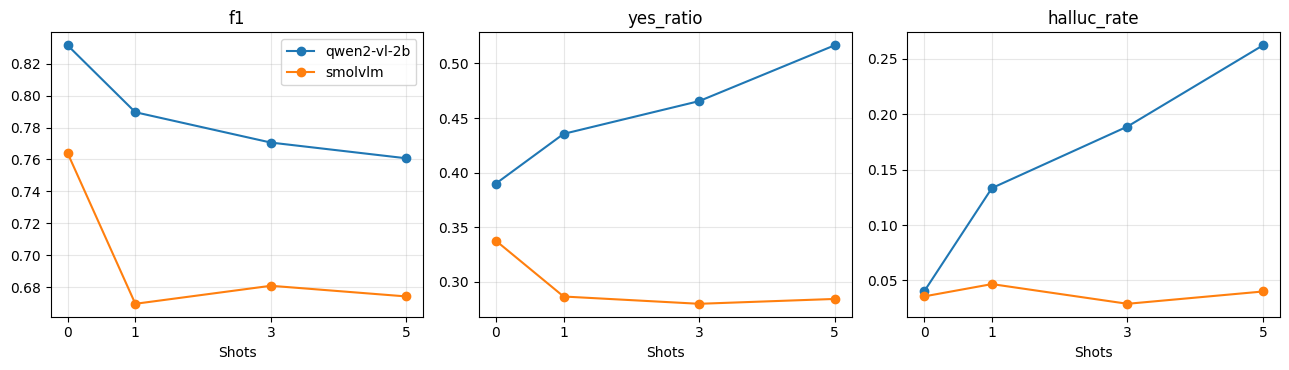

In [35]:
frames = []
for name in MODEL_REGISTRY:
    p = os.path.join(BASE_DIR, f"metrics_{name}.csv")
    if os.path.exists(p):
        t = pd.read_csv(p); t["model"] = name; frames.append(t[t["category"] == "average"])
if len(frames) >= 2:
    comp = pd.concat(frames)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, col in zip(axes, ["f1", "yes_ratio", "halluc_rate"]):
        for name, d in comp.groupby("model"):
            ax.plot(d["shot"], d[col], "o-", label=name)
        ax.set_title(col); ax.set_xticks(SHOTS); ax.set_xlabel("Shots"); ax.grid(alpha=0.3)
    axes[0].legend(); fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "model_comparison.png"), dpi=200); plt.show()
else:
    print("Only one model evaluated so far.")